# Bayesian Optimization

*Choosing the next experiment wisely.*

:::{admonition} What this chapter is about
:class: tip
In the last chapter, GPR gave us a prediction **and** an honest uncertainty. So can we *use that uncertainty to decide where to run the next experiment.?*

 **Bayesian Optimization (BO)** is a smart search for the best setting - the strongest alloy, the most active catalyst, the best process temperature - using **as few expensive experiments as possible**.

If GPR was the map, Bayesian Optimization is the *plan for where to explore next*.
:::

## The story so far

- **Regression** (linear, Ridge, Lasso) learned to **predict** a property from features.
- **GPR** did the same, but added **uncertainty** - it knows where it is only guessing.

Now we ask a different *kind* of question. Not *"what is the property at this setting?"* but:

> *"Which setting should I try next to find the best property, fast?"*

That shift - from **predicting** to **deciding** - is what Bayesian Optimization is about.

## The problem: every experiment is expensive

Imagine you are tuning a process to maximise a material's strength. The setting could be a temperature, a composition, or a pressure - call it $x$. For each $x$ you could run an experiment and measure the strength. But:

- Each experiment takes a day in the lab and real money.
- The link between $x$ and strength is unknown and bumpy.
- You cannot try hundreds of settings. Maybe you are allowed **ten**.

The blunt approaches waste that budget:

- **Grid search** tries evenly spaced settings - blind, and most tries land in bad regions.
- **Random search** throws darts - sometimes fine, but it ignores everything it has already learned.

Bayesian Optimization is different. After **every** experiment it stops and thinks: *"given all I now know, where is the single most promising place to look next?"*

Here is the situation. We have run a few experiments. Our GPR surrogate fills in the gaps - with honest uncertainty. Somewhere out there is the peak we want:

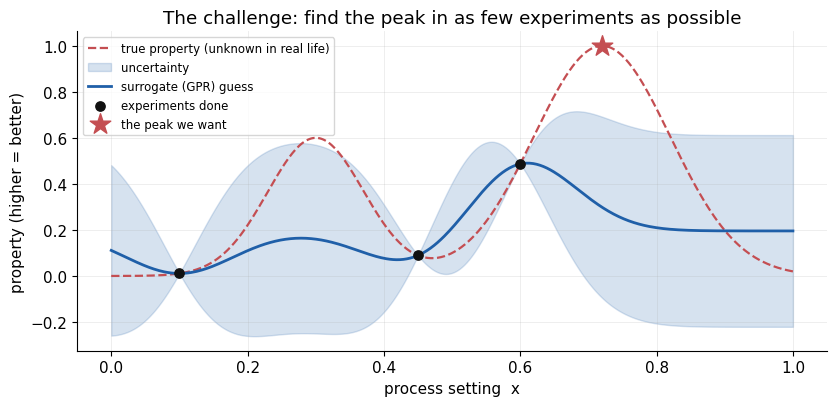

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel as C

plt.rcParams.update({"font.size":11,"axes.spines.top":False,"axes.spines.right":False,
                     "axes.grid":True,"grid.alpha":0.25,"grid.linewidth":0.6})
DATA_C,MEAN_C,BAND_C,TRUE_C,PICK_C,ACQ_C = "#111111","#1f5fa8","#1f5fa8","#c44e52","#d1495b","#2e8b57"

# an EXPENSIVE-to-measure property we want to MAXIMISE (illustrative, synthetic)
def measure(x):
    x = np.asarray(x, float)
    return 0.6*np.exp(-((x-0.30)**2)/0.010) + 1.0*np.exp(-((x-0.72)**2)/0.020)

grid  = np.linspace(0, 1, 400).reshape(-1, 1)
truth = measure(grid).ravel()
x_best_true = float(grid[np.argmax(truth)][0])

def surrogate():
    return GaussianProcessRegressor(kernel=C(1.0)*RBF(0.08), alpha=1e-6,
                                    normalize_y=True, optimizer=None)

# a few initial experiments we have already run
X = [0.10, 0.45, 0.60]
Y = [float(measure(x)) for x in X]
gp = surrogate(); gp.fit(np.array(X).reshape(-1,1), Y)
mean, std = gp.predict(grid, return_std=True)

fig, ax = plt.subplots(figsize=(8.5,4.2))
ax.plot(grid, truth, ls="--", color=TRUE_C, lw=1.6, label="true property (unknown in real life)")
ax.fill_between(grid.ravel(), mean-2*std, mean+2*std, color=BAND_C, alpha=0.18, label="uncertainty")
ax.plot(grid, mean, color=MEAN_C, lw=2, label="surrogate (GPR) guess")
ax.scatter(X, Y, color=DATA_C, zorder=5, s=45, label="experiments done")
ax.scatter([x_best_true],[truth.max()], marker="*", s=240, color=TRUE_C, zorder=6, label="the peak we want")
ax.set_xlabel("process setting  x"); ax.set_ylabel("property (higher = better)")
ax.set_title("The challenge: find the peak in as few experiments as possible")
ax.legend(loc="upper left", fontsize=8.5); plt.tight_layout(); plt.show()


The dashed line is the truth - which in real life we **cannot see**. All we have is the handful of black dots and the GPR surrogate (blue) with its uncertainty band. The goal: find the star, spending as few new experiments as possible.

## The key question: where to look next?

If you had to pick **one** setting to try next. Will you... 

- **Exploit:** go where the surrogate already predicts a high value. Safe - but you may just confirm what you already know.
- **Explore:** go where the surrogate is very **uncertain**. Risky - but that is where surprises, and better peaks, hide.

Think of choosing a restaurant. **Exploit** = your reliable favourite ☺️. **Explore** = the new place that might be amazing or terrible 😰. Always exploiting, you never discover somewhere better. Always exploring, you never enjoy a good meal. The art is the **balance**⚖️.

Bayesian Optimization writes this balance down as an **acquisition function** - a score for every candidate setting that mixes *"looks good"* with *"looks uncertain."* We then simply pick the setting with the highest score. One simple, popular recipe is:

> **acquisition = predicted value + (a bonus for uncertainty)**

Plotted under the surrogate, its highest point tells us where to run the next experiment:

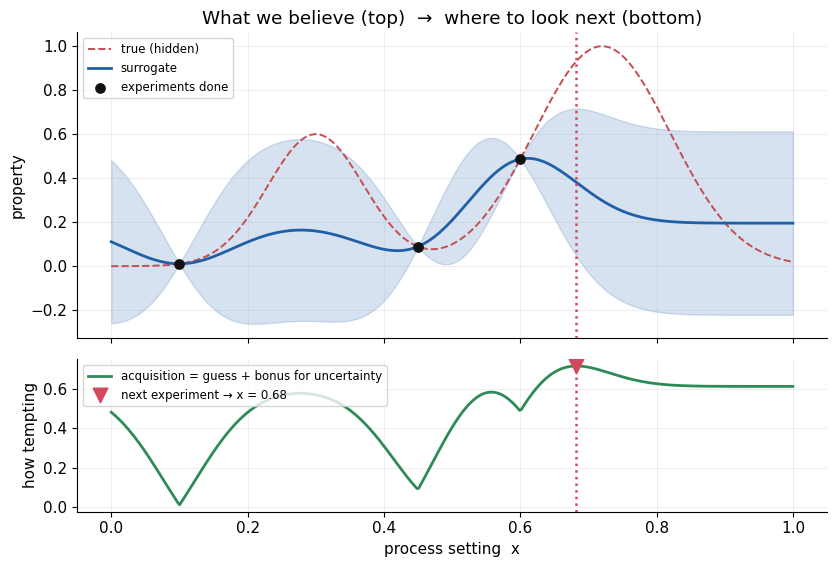

In [2]:
kappa = 2.0
acq = mean + kappa*std                        # value + a bonus for uncertainty (UCB)
x_next = float(grid[np.argmax(acq)][0])

fig,(ax1,ax2)=plt.subplots(2,1,figsize=(8.5,5.8),sharex=True,gridspec_kw={"height_ratios":[2,1]})
ax1.plot(grid, truth, ls="--", color=TRUE_C, lw=1.4, label="true (hidden)")
ax1.fill_between(grid.ravel(), mean-2*std, mean+2*std, color=BAND_C, alpha=0.18)
ax1.plot(grid, mean, color=MEAN_C, lw=2, label="surrogate")
ax1.scatter(X, Y, color=DATA_C, zorder=5, s=45, label="experiments done")
ax1.axvline(x_next, color=PICK_C, ls=":", lw=1.8)
ax1.set_ylabel("property"); ax1.set_title("What we believe (top)  \u2192  where to look next (bottom)")
ax1.legend(loc="upper left", fontsize=8.5)
ax2.plot(grid, acq, color=ACQ_C, lw=2, label="acquisition = guess + bonus for uncertainty")
ax2.axvline(x_next, color=PICK_C, ls=":", lw=1.8)
ax2.scatter([x_next],[acq.max()], color=PICK_C, s=110, marker="v", zorder=6,
            label=f"next experiment \u2192 x = {x_next:.2f}")
ax2.set_xlabel("process setting  x"); ax2.set_ylabel("how tempting")
ax2.legend(loc="upper left", fontsize=8.5); plt.tight_layout(); plt.show()


Look at the two panels together. The right-hand side has **no data**, so the surrogate is unsure there - and the acquisition (bottom) rewards that uncertainty. Its peak (the marker) points to the next experiment. Here, BO chooses to **explore** the promising, unexplored region on the right - which is exactly where the true peak is hiding. Smart.

:::{note} The bonus knob
The size of the uncertainty bonus is a dial (often written $\kappa$, "kappa"). Turn it **up** and BO explores more; turn it **down** and BO exploits more. It is the explore-vs-exploit balance, in a single number.
:::

## The loop: the whole method in six steps

Bayesian Optimization is just this cycle, repeated until the budget runs out:

1. **Fit** the GPR surrogate to every experiment done so far.
2. **Predict** the value and uncertainty everywhere (cheap - no lab needed).
3. **Score** every candidate setting with the acquisition function.
4. **Pick** the setting with the highest score.
5. **Run** that one real experiment (the expensive step).
6. **Add** the result, and go back to step 1.

Watch it work. Each panel is one turn of the loop; the red star is the setting BO decides to try next:

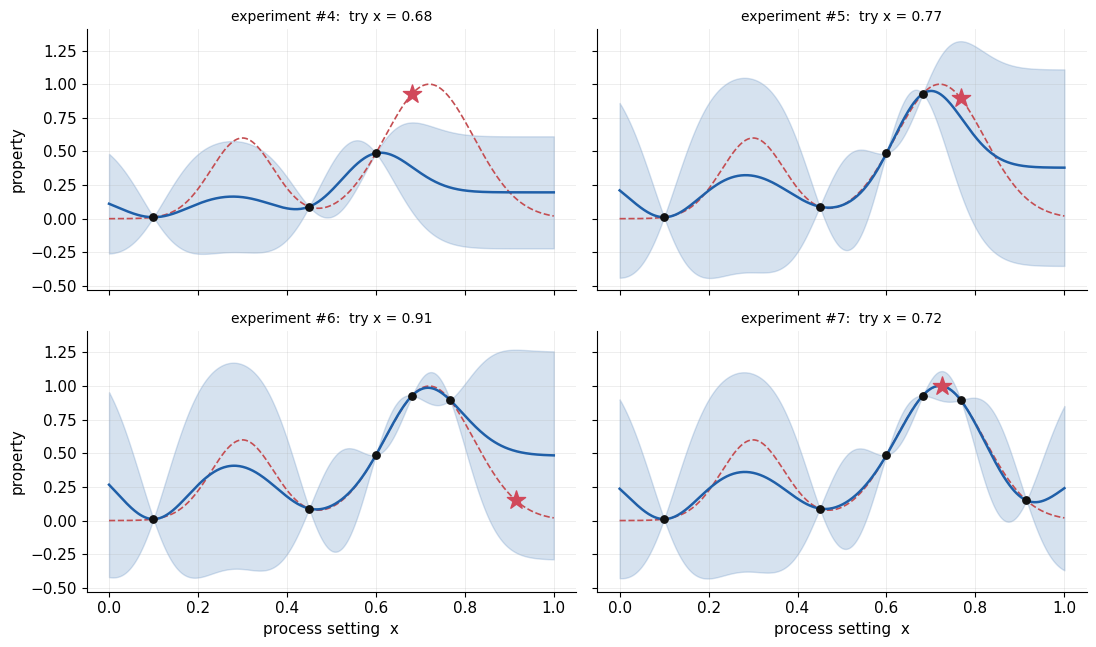

In [3]:
# run a few BO steps and watch it home in on the peak
Xb=[0.10,0.45,0.60]; Yb=[float(measure(x)) for x in Xb]
fig, axes = plt.subplots(2,2, figsize=(11,6.6), sharex=True, sharey=True)
for ax in axes.ravel():
    g=surrogate(); g.fit(np.array(Xb).reshape(-1,1), Yb)
    m,s=g.predict(grid, return_std=True)
    xn=float(grid[np.argmax(m+2.0*s)][0]); yn=float(measure(xn))
    ax.plot(grid, truth, ls="--", color=TRUE_C, lw=1.2)
    ax.fill_between(grid.ravel(), m-2*s, m+2*s, color=BAND_C, alpha=0.18)
    ax.plot(grid, m, color=MEAN_C, lw=1.8)
    ax.scatter(Xb, Yb, color=DATA_C, zorder=5, s=28)
    ax.scatter([xn],[yn], color=PICK_C, marker="*", s=190, zorder=6)
    ax.set_title(f"experiment #{len(Xb)+1}:  try x = {xn:.2f}", fontsize=10)
    Xb.append(xn); Yb.append(yn)
for ax in axes[-1]: ax.set_xlabel("process setting  x")
for ax in axes[:,0]: ax.set_ylabel("property")
plt.tight_layout(); plt.show()


Notice what it does *not* do: it does not waste experiments on regions it already believes are hopeless. Within a few turns it has zeroed in on the true peak. That focus - spending the budget where it matters - is the whole point.

## Doing it in code

The loop is short - really just GPR from last chapter wrapped in a `for` loop with an acquisition step. Everything here is plain `scikit-learn`:

In [4]:
import numpy as np
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel

# stand-in for a real, EXPENSIVE lab measurement (we want its highest value)
def run_experiment(x):
    return 0.6*np.exp(-((x-0.30)**2)/0.010) + 1.0*np.exp(-((x-0.72)**2)/0.020)

grid = np.linspace(0, 1, 400).reshape(-1, 1)     # settings we could try
X = [0.10, 0.45, 0.60]                            # a few experiments already done
y = [float(run_experiment(x)) for x in X]
kappa = 2.0                                       # how adventurous to be

for step in range(6):
    gp = GaussianProcessRegressor(ConstantKernel(1.0)*RBF(0.08),
                                  alpha=1e-6, normalize_y=True, optimizer=None)
    gp.fit(np.array(X).reshape(-1, 1), y)         # 1) fit surrogate to what we know
    mean, std = gp.predict(grid, return_std=True) # 2) predictions + uncertainty
    acquisition = mean + kappa * std              # 3) balance value vs. uncertainty
    x_next = float(grid[np.argmax(acquisition)][0])  # 4) most promising setting
    y_next = float(run_experiment(x_next))        # 5) run the costly experiment
    X.append(x_next); y.append(y_next)            # 6) remember it, then repeat
    print(f"step {step+1}: tried x = {x_next:.3f}  ->  property = {y_next:.3f}"
          f"   | best so far = {max(y):.3f}")

print(f"\nBest setting found: x = {X[int(np.argmax(y))]:.3f}  (the true best is near x = 0.72)")


step 1: tried x = 0.682  ->  property = 0.929   | best so far = 0.929
step 2: tried x = 0.767  ->  property = 0.896   | best so far = 0.929
step 3: tried x = 0.915  ->  property = 0.150   | best so far = 0.929
step 4: tried x = 0.724  ->  property = 0.999   | best so far = 0.999
step 5: tried x = 0.278  ->  property = 0.572   | best so far = 0.999
step 6: tried x = 0.714  ->  property = 0.998   | best so far = 0.999

Best setting found: x = 0.724  (the true best is near x = 0.72)


Read the six commented lines inside the loop - they are exactly the six steps above. Each pass prints the setting BO chose and the value it found, and you can watch **"best so far"** climb toward the true peak near x = 0.72.

:::{tip} Acquisition functions come in a few flavours
Our "value + bonus for uncertainty" rule is called **Upper Confidence Bound (UCB)** - the easiest to picture. Two other common ones are **Expected Improvement (EI)** (often the default) and **Probability of Improvement (PI)**. They use different formulas but chase the same goal: balance exploiting and exploring. A short note on each is in the dropdown at the end.
:::

:::{note} A note on "max" vs "min"
We framed everything as *maximising* a property. Many tools (like `scikit-optimize`) *minimise* a cost instead - same idea, just flip the sign. Maximising strength is the same as minimising "negative strength" or minimizing weakness.
:::

## Does it actually help?

Fair to be skeptical. Let us test BO against plain **random search**, giving both the **same budget** of experiments, and averaging over many runs so we are not fooled by luck:

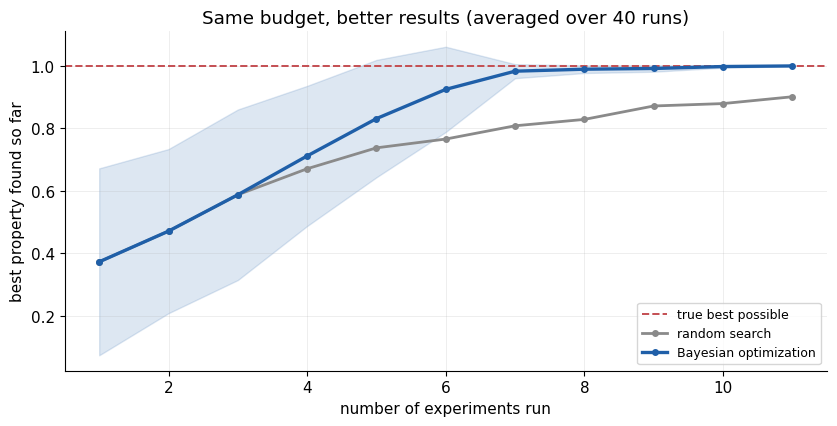

In [5]:
# Fair test: BO vs random search, SAME budget, averaged over many runs
def best_so_far(vals):
    out=[]; cur=-1e9
    for v in vals: cur=max(cur,v); out.append(cur)
    return np.array(out)

n_seeds, n_steps, n_init = 40, 8, 3
bo_all=[]; rnd_all=[]
for seed in range(n_seeds):
    rng=np.random.default_rng(seed)
    x0=list(rng.uniform(0,1,n_init))
    Xb=x0[:]; Yb=[float(measure(x)) for x in Xb]           # Bayesian optimization
    for _ in range(n_steps):
        g=surrogate(); g.fit(np.array(Xb).reshape(-1,1),Yb)
        m,s=g.predict(grid,return_std=True)
        xn=float(grid[np.argmax(m+2.0*s)][0]); Xb.append(xn); Yb.append(float(measure(xn)))
    bo_all.append(best_so_far(Yb))
    Xr=x0+list(rng.uniform(0,1,n_steps)); Yr=[float(measure(x)) for x in Xr]  # random
    rnd_all.append(best_so_far(Yr))
bo_all=np.array(bo_all); rnd_all=np.array(rnd_all)
ev=np.arange(1, bo_all.shape[1]+1)

fig, ax = plt.subplots(figsize=(8.5,4.4))
ax.axhline(truth.max(), ls="--", color=TRUE_C, lw=1.4, label="true best possible")
ax.plot(ev, rnd_all.mean(0), color="#8a8a8a", lw=2, marker="o", ms=4, label="random search")
ax.plot(ev, bo_all.mean(0), color=MEAN_C, lw=2.4, marker="o", ms=4, label="Bayesian optimization")
ax.fill_between(ev, bo_all.mean(0)-bo_all.std(0), bo_all.mean(0)+bo_all.std(0), color=BAND_C, alpha=0.15)
ax.set_xlabel("number of experiments run"); ax.set_ylabel("best property found so far")
ax.set_title("Same budget, better results (averaged over 40 runs)")
ax.legend(loc="lower right", fontsize=9); plt.tight_layout(); plt.show()


With the same number of experiments, Bayesian Optimization climbs to the true best **faster** and more reliably than random search. When each experiment is a day in the lab, reaching the peak in around five tries instead of nine is a very big deal.

(These are illustrative, synthetic runs - but the pattern is exactly why BO is used for real.)

## How it compares

| Method | Uses what it has learned? | Good when experiments are… | Typical use |
|---|---|---|---|
| **Grid search** | No - fixed, blind grid | cheap, few settings | quick baseline |
| **Random search** | No - random darts | cheap-ish | surprisingly decent baseline |
| **Bayesian Optimization** | **Yes** - refits after each result | **expensive / precious** | tuning experiments, simulations, models |

And here is how the whole course thread ties together:

> **Regression** predicts a property. **GPR** predicts it *with uncertainty*. **Bayesian Optimization** *uses that uncertainty to decide what to do next.* Each idea is the foundation for the one after it.

## Where this shows up in materials science

This loop - predict, choose, measure, repeat - is the engine behind **materials discovery** and **self-driving labs** (autonomous experimentation), where software proposes the next composition or process setting, a robot runs it, and the result feeds straight back into the model. The same "active learning" idea helps choose which expensive **simulations** to run, or which candidate compounds to synthesise first. In every case the aim is identical: **learn the most, from the fewest experiments.**

:::{warning} Honest limitations
- BO shines with a **small number of settings to tune** (a few dimensions). In very high dimensions it gets much harder.
- It leans entirely on the **surrogate**. A poor GPR (wrong kernel) leads to poor choices.
- It still needs **several** experiments - efficient, not magic - and it can linger on a local bump if it explores too little.
- Very noisy or jumpy objectives break the smoothness GPR relies on.
:::

## Putting it together

- BO answers *"which experiment next?"* when each experiment is **expensive**.
- It uses a cheap **surrogate** (GPR) to stand in for the costly experiment.
- An **acquisition function** balances **exploiting** (good) and **exploring** (uncertain) - e.g. *value + a bonus for uncertainty*.
- The **loop**: fit → predict → score → pick → measure → repeat.
- On the same budget, BO **reaches the best setting in fewer experiments** than random search.
- It is the natural finale of our thread: **regression → uncertainty (GPR) → decisions (BO)**.

One sentence to carry with you: **Bayesian Optimization spends each precious experiment where it will teach you the most.**

## Check your understanding

:::{dropdown} 1. Why not just use grid search or random search?
They are **blind** - they ignore everything already measured. BO **refits after each result** and aims its next experiment where it is most promising. When experiments are expensive and few, that focus wins.
:::

:::{dropdown} 2. What two things does an acquisition function balance?
**Exploitation** (settings with a high predicted value) and **exploration** (settings with high uncertainty). It scores every candidate by mixing the two.
:::

:::{dropdown} 3. In "value + kappa × uncertainty", you increase kappa. Does BO explore more or exploit more?
**Explore more.** A bigger uncertainty bonus makes uncertain regions more tempting, so BO wanders into the unknown rather than sticking near the current best.
:::

:::{dropdown} 4. What job does GPR do inside Bayesian Optimization?
It is the **surrogate**: a cheap model that predicts the value *and* the uncertainty at every setting, so the acquisition function has something to score. No uncertainty, no BO.
:::

:::{dropdown} 5. You can afford 8 experiments to maximise catalyst activity over one temperature knob. Why is BO a good fit?
The experiments are **few and expensive**, and there is only **one setting** to tune (low-dimensional). That is exactly where BO is strongest - it will spend those 8 tries on the most promising, most informative temperatures.
:::

:::{dropdown} For the curious: the three common acquisition functions (optional)
Let $\mu(x)$ be the surrogate's predicted value and $\sigma(x)$ its uncertainty (both come straight from GPR). Let $f^{+}$ be the best value seen so far.

- **Upper Confidence Bound (UCB):** $\;\mu(x) + \kappa\,\sigma(x)$. The one we used. $\kappa$ sets the explore/exploit balance.
- **Probability of Improvement (PI):** the *chance* that $x$ beats $f^{+}$.
- **Expected Improvement (EI):** not just the chance of beating $f^{+}$, but by **how much**, on average. This is the common default in practice.

All three grow when $\mu(x)$ is high (exploit) **or** when $\sigma(x)$ is high (explore) - they just weigh the two differently.
:::

:::{seealso} Where to read more
- Frazier, P. I. (2018). *A Tutorial on Bayesian Optimization.* arXiv:1807.02811 - a clear, modern walkthrough.
- Shahriari, B., Swersky, K., Wang, Z., Adams, R. P. & de Freitas, N. (2016). *Taking the Human Out of the Loop: A Review of Bayesian Optimization.* Proceedings of the IEEE, 104(1), 148–175.
- **scikit-optimize** (`skopt.gp_minimize`) is the easiest way to try BO in Python; **BoTorch** / **Ax** and **GPyOpt** are more advanced toolkits.
:::

:::{admonition} That wraps the thread
:class: tip
From a straight line, to penalties that tame it, to a model that admits its own doubt, to a method that turns that doubt into smart decisions - you have followed one idea all the way from **fitting data** to **designing experiments**. That is a genuinely powerful toolkit for materials work.
:::